# Task 5: Topic Modeling on News Articles

**Objective:** Discover hidden themes in a collection of BBC-style news articles using unsupervised NLP.

**Approaches:**
- **LDA** — Latent Dirichlet Allocation (Gensim)
- **NMF** — Non-negative Matrix Factorization (scikit-learn)

**Evaluation:** Coherence Score (C_v)

---

## 1. Setup & Imports

In [1]:
import os
import sys
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['figure.dpi'] = 120

# Add src to path
sys.path.insert(0, os.path.abspath('../src'))

from preprocess import download_nltk_resources, preprocess_text, preprocess_corpus
from topic_model import TopicModelEngine
from evaluate import compute_coherence, print_topics, print_coherence

download_nltk_resources()
print('Setup complete.')

Setup complete.


## 2. Load Dataset

In [2]:
df = pd.read_csv('../data/sample_news.csv')
print(f'Loaded {len(df)} articles')
df.head()

Loaded 25 articles


,category,text
0,business,The stock market saw significant gains today a...
1,business,Global trade tensions are easing as major econ...
2,business,Oil prices surged amid supply disruptions in t...
3,business,Central banks around the world are adjusting m...
4,business,Technology mergers and acquisitions are accele...


## 3. Exploratory Data Analysis (EDA)

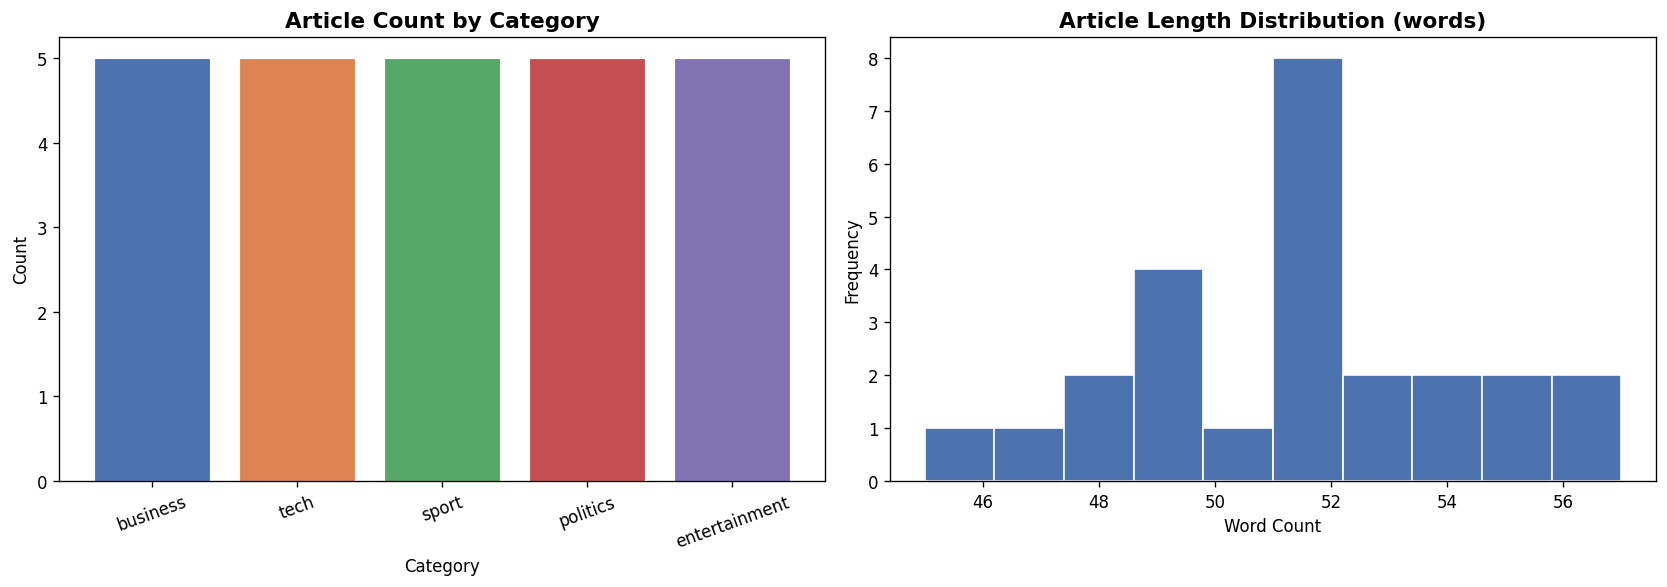

Average article length: 51 words


In [3]:
# --- Category distribution ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cat_counts = df['category'].value_counts()
colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52', '#8172B2']

axes[0].bar(cat_counts.index, cat_counts.values, color=colors, edgecolor='white', linewidth=0.7)
axes[0].set_title('Article Count by Category', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Category')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=20)

# --- Text length distribution ---
df['text_length'] = df['text'].apply(lambda x: len(x.split()))
axes[1].hist(df['text_length'], bins=10, color='#4C72B0', edgecolor='white')
axes[1].set_title('Article Length Distribution (words)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Word Count')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.savefig('../assets/eda_plots.png', bbox_inches='tight')
plt.show()
print(f'Average article length: {df["text_length"].mean():.0f} words')

## 4. Text Preprocessing

In [4]:
raw_texts = df['text'].tolist()
tokenized_docs = preprocess_corpus(raw_texts)

# Show a sample
print('Original:', raw_texts[0][:120], '...')
print('\nCleaned tokens:', tokenized_docs[0][:15])
print(f'\nAverage tokens per doc after cleaning: {sum(len(d) for d in tokenized_docs)/len(tokenized_docs):.1f}')

Original: The stock market saw significant gains today as tech companies reported strong quarterly earnings. Investors remain opti ...

Cleaned tokens: ['stock', 'market', 'saw', 'significant', 'gain', 'today', 'tech', 'company', 'reported', 'strong', 'quarterly', 'earnings', 'investor', 'remain', 'optimistic']

Average tokens per doc after cleaning: 37.2


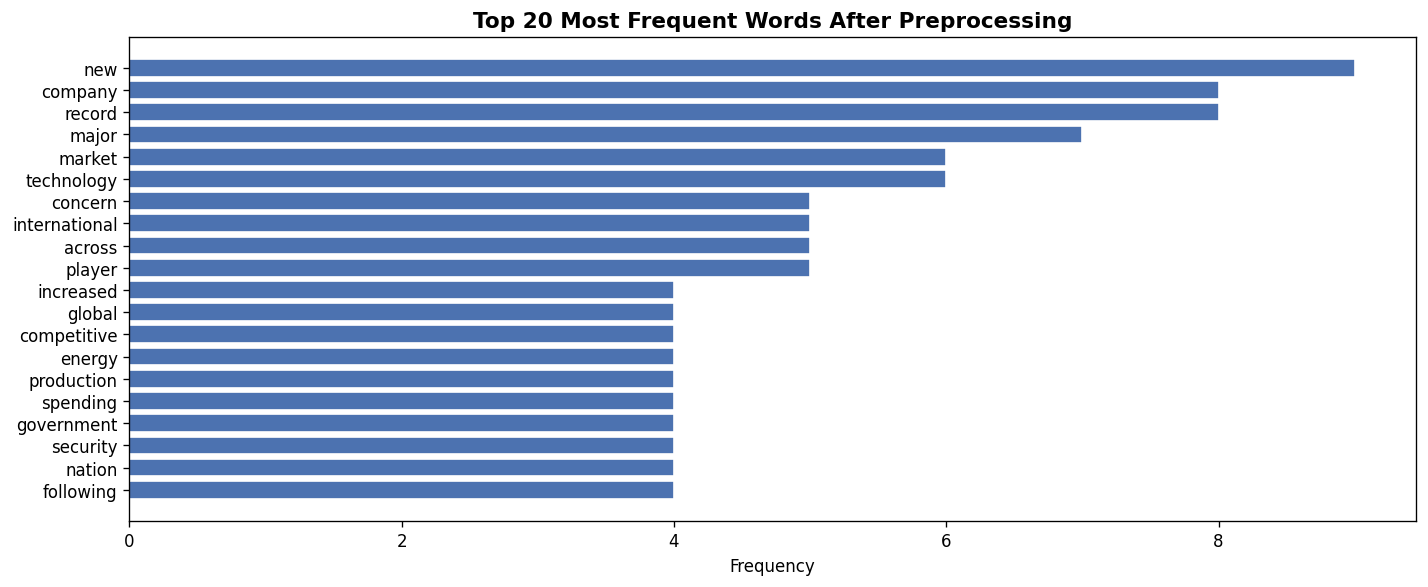

In [5]:
# --- Top 20 most frequent words across corpus ---
from collections import Counter

all_tokens = [tok for doc in tokenized_docs for tok in doc]
freq = Counter(all_tokens).most_common(20)
words, counts = zip(*freq)

plt.figure(figsize=(12, 5))
bars = plt.barh(list(reversed(words)), list(reversed(counts)), color='#4C72B0', edgecolor='white')
plt.title('Top 20 Most Frequent Words After Preprocessing', fontsize=13, fontweight='bold')
plt.xlabel('Frequency')
plt.tight_layout()
plt.savefig('../assets/top_words.png', bbox_inches='tight')
plt.show()

## 5. LDA Topic Modeling (Gensim)

In [6]:
N_TOPICS = 5

engine = TopicModelEngine(n_topics=N_TOPICS)
engine.build_lda(tokenized_docs, passes=15)

lda_topics = engine.get_lda_topics(n_words=10)
print_topics(lda_topics, model_name='LDA (Gensim)')

  TOP WORDS PER TOPIC — LDA (Gensim)
  Topic  1: new | economic | record | consumer | trade | cultural | boost | spending | increasingly | address
  Topic  2: across | tour | within | feature | continent | fan | audience | tournament | player | team
  Topic  3: security | record | new | government | rate | spending | series | challenge | response | organized
  Topic  4: athlete | data | method | sport | competitor | performance | player | competitive | tournament | prize
  Topic  5: company | energy | technology | concern | market | global | globally | competing | investment | major



In [7]:
# Coherence score
lda_coherence = compute_coherence(engine.lda_model, tokenized_docs, engine.dictionary)
print_coherence(lda_coherence, model_name='LDA')

  [LDA] Coherence Score (C_v): 0.3039
  Quality Assessment: [LOW]   Topics may need more data or tuning



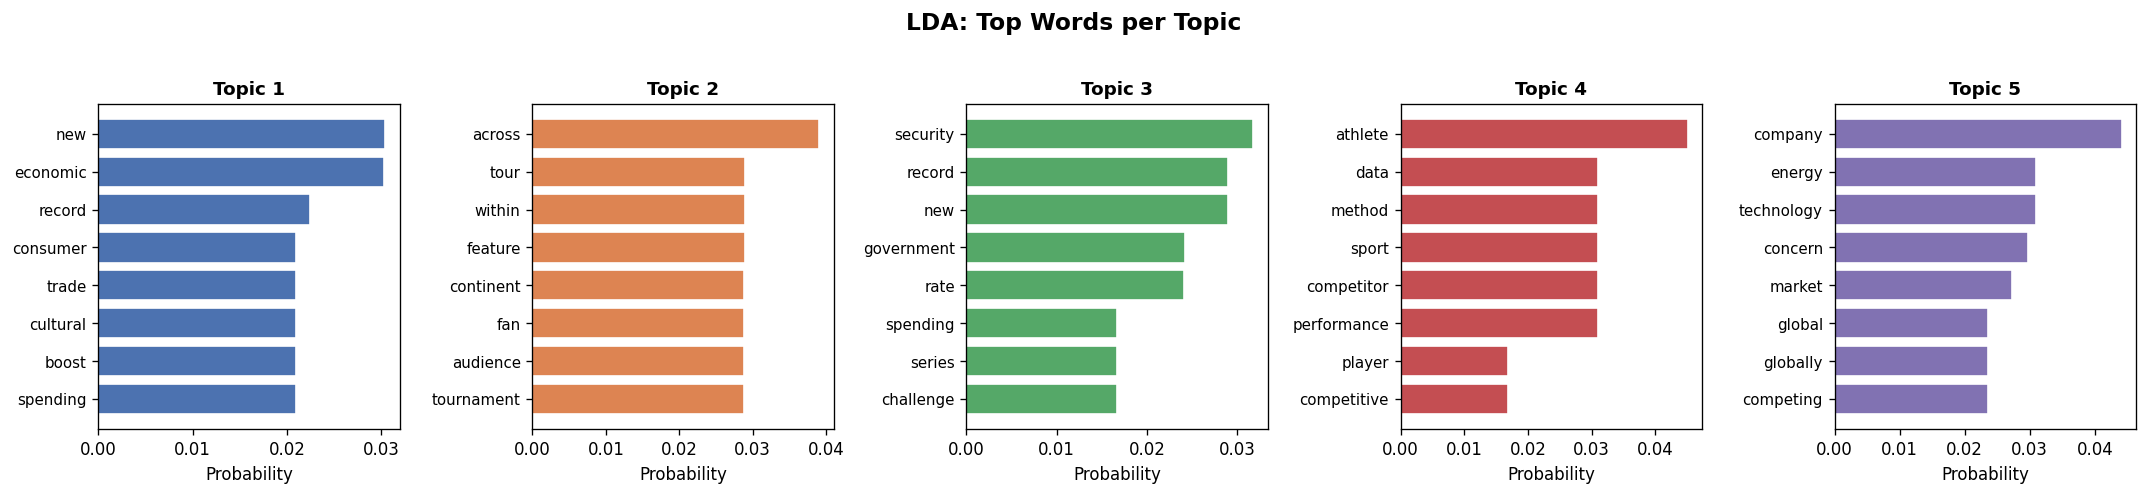

In [8]:
# --- Visualize LDA topic-word weights ---
from gensim import corpora

fig, axes = plt.subplots(1, N_TOPICS, figsize=(18, 4), sharey=False)
topic_colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52', '#8172B2']

for i, topic in enumerate(lda_topics):
    top_words = topic['words'][:8]
    # Get weights for these words
    term_probs = engine.lda_model.show_topic(i, topn=8)
    top_ws = [w for w, _ in term_probs]
    top_ps = [p for _, p in term_probs]
    
    axes[i].barh(top_ws[::-1], top_ps[::-1], color=topic_colors[i], edgecolor='white')
    axes[i].set_title(f'Topic {i+1}', fontweight='bold', fontsize=11)
    axes[i].set_xlabel('Probability')
    axes[i].tick_params(axis='y', labelsize=9)

plt.suptitle('LDA: Top Words per Topic', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../assets/lda_topics.png', bbox_inches='tight')
plt.show()

## 6. NMF Topic Modeling — Bonus (LDA vs NMF)

In [10]:
engine.build_nmf(raw_texts)
nmf_topics = engine.get_nmf_topics(n_words=10)
print_topics(nmf_topics, model_name='NMF (scikit-learn)')

  TOP WORDS PER TOPIC — NMF (scikit-learn)
  Topic  1: technology | companies | energy | growing | concerns | grow | seek | global | competing | markets
  Topic  2: players | prize | drawing | cultural | cities | traditional | competitive | major | younger | audiences
  Topic  3: security | data | record | spending | organized | training | individual | critical | reached | computing
  Topic  4: trade | remain | growth | economic | sector | job | manufacturing | new | boost | despite
  Topic  5: series | tour | following | fans | streaming | records | productions | multiple | social | praised



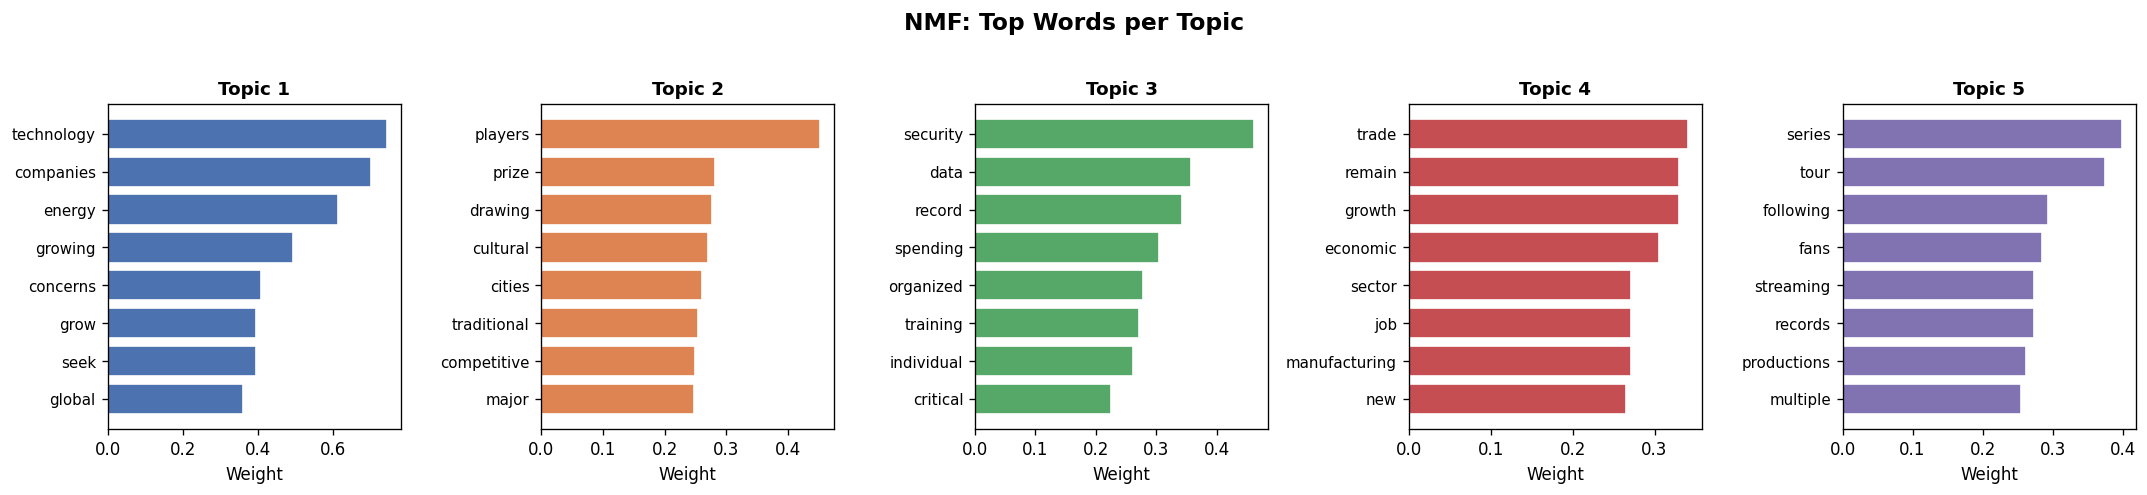

In [15]:
# --- Visualize NMF topic-word weights ---
feature_names = engine.tfidf_vectorizer.get_feature_names_out()

fig, axes = plt.subplots(1, N_TOPICS, figsize=(18, 4), sharey=False)

for i, component in enumerate(engine.nmf_model.components_):
    top_idx = component.argsort()[-8:][::-1]
    top_ws = [feature_names[j] for j in top_idx]
    top_ps = [component[j] for j in top_idx]
    
    axes[i].barh(top_ws[::-1], top_ps[::-1], color=topic_colors[i], edgecolor='white')
    axes[i].set_title(f'Topic {i+1}', fontweight='bold', fontsize=11)
    axes[i].set_xlabel('Weight')
    axes[i].tick_params(axis='y', labelsize=9)

plt.suptitle('NMF: Top Words per Topic', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../assets/nmf_topics.png', bbox_inches='tight')
plt.show()

## 7. Document-Topic Assignment

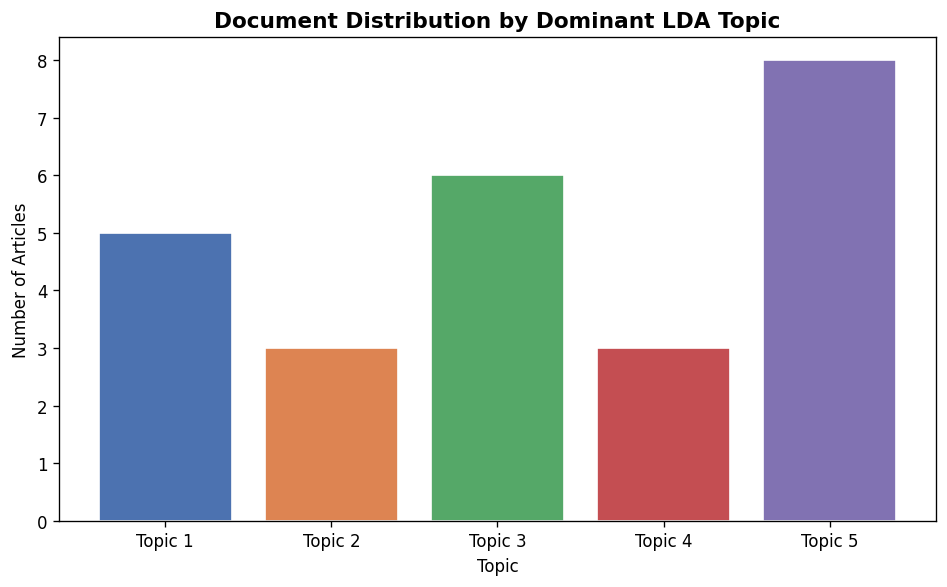

,category,dominant_topic_label,text
0,business,Topic 5,The stock market saw significant gains today a...
1,business,Topic 5,Global trade tensions are easing as major econ...
2,business,Topic 5,Oil prices surged amid supply disruptions in t...
3,business,Topic 3,Central banks around the world are adjusting m...
4,business,Topic 5,Technology mergers and acquisitions are accele...
5,tech,Topic 3,Scientists have developed a new quantum comput...
6,tech,Topic 1,Artificial intelligence models are becoming in...
7,tech,Topic 5,A new generation of electric vehicles with ext...
8,tech,Topic 3,Cybersecurity threats are evolving as hackers ...
9,tech,Topic 5,Space technology companies are developing reus...


In [16]:
df['dominant_topic'] = engine.get_doc_topic_distribution()
df['dominant_topic_label'] = df['dominant_topic'].apply(lambda x: f'Topic {x+1}')

# Distribution of dominant topics
topic_dist = df['dominant_topic_label'].value_counts().sort_index()

plt.figure(figsize=(8, 5))
plt.bar(topic_dist.index, topic_dist.values, color=topic_colors[:len(topic_dist)], edgecolor='white')
plt.title('Document Distribution by Dominant LDA Topic', fontsize=13, fontweight='bold')
plt.xlabel('Topic')
plt.ylabel('Number of Articles')
plt.tight_layout()
plt.savefig('../assets/topic_distribution.png', bbox_inches='tight')
plt.show()

df[['category', 'dominant_topic_label', 'text']].head(10)

## 8. LDA vs NMF Comparison Summary

In [17]:
print('=' * 55)
print('  LDA vs NMF — Comparison Summary')
print('=' * 55)
print(f'  LDA Coherence Score (C_v):  {lda_coherence:.4f}')
print()
print('  LDA  — Probabilistic model, good for large corpora')
print('         Soft assignments: docs can belong to multiple topics')
print()
print('  NMF  — Matrix factorization, deterministic & faster')
print('         Produces sharper, more focused topic-word weights')
print('         Good for short documents and well-defined categories')
print('=' * 55)

  LDA vs NMF — Comparison Summary
  LDA Coherence Score (C_v):  0.3039

  LDA  — Probabilistic model, good for large corpora
         Soft assignments: docs can belong to multiple topics

  NMF  — Matrix factorization, deterministic & faster
         Produces sharper, more focused topic-word weights
         Good for short documents and well-defined categories


## 9. Save Models

In [18]:
models_dir = '../models'
engine.save(models_dir)
df.to_csv('../data/results.csv', index=False)
print(f'Models saved to {models_dir}')
print('Results saved to ../data/results.csv')
print('Pipeline complete!')

Models saved to ../models
Results saved to ../data/results.csv
Pipeline complete!
